# 04: Robustness experiments

Self-contained notebook for the control-penalty, cell-disjoint, and ten-seed leave-one-cell-out experiments, the split audit and index export, and Figures 4, 5, and 7. It reuses the
preprocessing, network, physics penalty, and training loop of
`02_followup_experiments.ipynb` unchanged, so new numbers are directly
comparable with Tables 3 to 7.

| Section | Purpose | Output |
|---|---|---|
| 1 | (safety) | sanity checks on the parsed impedance |
| 2 | reproducibility, chronology | `MEASURE_ID` order, exact partition composition, split-index CSVs |
| 3 | physical prior interpretation | matched-strength control regularisers vs the physics penalty (10 seeds) |
| 4 | independence of the principal evaluation | fully cell-disjoint split: train B2+B3, validate B5, test B6 (10 seeds) |
| 5 | independence, cross-cell | leave-one-cell-out with 10 seeds, physics vs no-physics vs RF vs GB |
| 6 | terminology | Figures 4 to 7 redrawn with PGNN labels |
| 7 | reproducibility | package versions, requirements file, one zip of everything |

**Conventions (all sections):** Youden threshold from the exact validation ROC
thresholds (as in Tables 3, 4, 6, 7); SD with denominator n − 1; paired t-tests
across seeds; bootstrap CIs resample whole test sweeps.

**How to run (Colab):** Runtime → Run all. Upload `impedance.csv` and
`frequencies.csv` when asked. Optionally also upload the earlier result zips
(`reviewer3_results.zip`, `reviewer_results_v2.zip`, `reviewer_results_v4.zip`)
so Figures 5B and 6 are drawn from the exact numbers already in the paper;
without them those panels are recomputed. At the end `reviewer4_results.zip`
downloads. 

**Runtime:** about 45 to 75 minutes on a CPU runtime. Each section saves its
JSON as soon as it finishes; set its flag in `RUN` to `False` to skip it on a re-run.

In [1]:
RUN = {
    "audit": True,          # section 2
    "controls": True,       # section 3
    "cell_disjoint": True,  # section 4
    "loco": True,           # section 5
    "figures": True,        # section 6
}
N_SEEDS = 10      # seeds 0-9, as in Tables 5 and 6
N_BOOT = 2000

## 0. Setup and data

In [2]:
import os, json, time, random, warnings, zipfile, platform, glob, shutil
import numpy as np
import pandas as pd
import torch, torch.nn as nn, torch.optim as optim
import sklearn, scipy, matplotlib
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, roc_curve, f1_score, accuracy_score, recall_score, confusion_matrix
from scipy import stats
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

QUICK = os.environ.get("QUICK") == "1"          # fast smoke test only; never use for the paper
MAX_EPOCHS = 3 if QUICK else 300
if QUICK:
    N_SEEDS, N_BOOT = 2, 50

os.makedirs("results", exist_ok=True); os.makedirs("prior", exist_ok=True)
T0 = time.time()
def elapsed(): return f"{(time.time() - T0) / 60:.1f} min"
def save(name, obj):
    with open(f"results/{name}.json", "w") as f:
        json.dump(obj, f, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o))
    print(f"saved results/{name}.json ({elapsed()})")

DATA_DIR = os.environ.get("DATA_DIR", "data")
def find(pattern):
    hits = sorted(glob.glob(os.path.join(DATA_DIR, pattern)))
    return hits[0] if hits else None
IMP_PATH, FREQ_PATH = find("impedance*.csv"), find("frequencies*.csv")
if not (IMP_PATH and FREQ_PATH):
    os.makedirs(DATA_DIR, exist_ok=True)
    from google.colab import files
    print("Upload impedance.csv and frequencies.csv (optionally also the earlier result zips):")
    up = files.upload()
    for fn, content in up.items():
        target = os.path.join("prior" if fn.endswith(".zip") else DATA_DIR, fn)
        with open(target, "wb") as f: f.write(content)
    IMP_PATH, FREQ_PATH = find("impedance*.csv"), find("frequencies*.csv")
for zp in glob.glob("prior/*.zip"):
    with zipfile.ZipFile(zp) as z: z.extractall("prior")
print("impedance:", IMP_PATH, "| frequencies:", FREQ_PATH)
print("prior result files:", sorted(os.path.basename(p) for p in glob.glob("prior/**/*.json", recursive=True)))

Upload impedance.csv and frequencies.csv (optionally also the earlier result zips):


Saving frequencies.csv to frequencies.csv
Saving impedance.csv to impedance.csv
impedance: data/impedance.csv | frequencies: data/frequencies.csv
prior result files: []


## 1. Preprocessing (identical to the follow-up notebook) and sanity checks
The checks stop the notebook if the impedance column is missing or parses to
nonsense, which is what broke the repository version of this pipeline.

In [3]:
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(max(1, os.cpu_count() or 1))

impedance = pd.read_csv(IMP_PATH)
frequencies = pd.read_csv(FREQ_PATH)
assert "IMPEDANCE_VALUE" in impedance.columns, f"no IMPEDANCE_VALUE column: {list(impedance.columns)}"
assert "FREQUENCY_VALUE" in frequencies.columns, f"no FREQUENCY_VALUE column: {list(frequencies.columns)}"
impedance["FILE_ROW"] = np.arange(len(impedance))
df = impedance.merge(frequencies, on="FREQUENCY_ID", how="left")
df["SWEEP_ID"] = df["BATTERY_ID"].astype(str) + "_" + df["MEASURE_ID"].astype(str) + "_" + df["SOC"].astype(str)

def parse_complex(s):
    if pd.isna(s): return np.nan
    s = str(s).replace(" ", "").replace("(", "").replace(")", "")
    try: return complex(s)
    except ValueError: return np.nan

df["Z_complex"] = df["IMPEDANCE_VALUE"].apply(parse_complex)
df["Re_Z"] = df["Z_complex"].apply(lambda z: z.real)
df["Im_Z"] = df["Z_complex"].apply(lambda z: z.imag)
df["abs_Z"] = df["Z_complex"].apply(lambda z: abs(z))
df = df.dropna(subset=["Re_Z", "Im_Z", "abs_Z", "SOC"]).reset_index(drop=True)
freq_col = "FREQUENCY_VALUE"
df["log10_f"] = np.log10(df[freq_col].astype(float))
df["phi"] = np.arctan2(df["Im_Z"], df["Re_Z"])
FEATS = ["log10_f", "Re_Z", "Im_Z", "abs_Z", "phi"]

# --- sanity checks -------------------------------------------------------------
print("rows:", len(df), "| sweeps:", df["SWEEP_ID"].nunique(), "| batteries:", sorted(df["BATTERY_ID"].unique().tolist()))
print("Re(Z) range [ohm]:", round(df.Re_Z.min(), 4), "to", round(df.Re_Z.max(), 4))
print("Im(Z) range [ohm]:", round(df.Im_Z.min(), 4), "to", round(df.Im_Z.max(), 4))
print("frequency range [Hz]:", df[freq_col].min(), "to", df[freq_col].max())
assert len(df) == 3360 or QUICK, "expected 3,360 measurements"
assert df.Im_Z.abs().max() > 0, "Im(Z) is identically zero: the impedance column was not parsed"
assert 1e-3 < df.Re_Z.median() < 1.0, "Re(Z) median outside a plausible range for an 18650 cell (ohm)"
assert df.groupby("SWEEP_ID").size().eq(14).all() or QUICK, "every sweep should have 14 frequency points"

# --- windows, with metadata carried explicitly (no string parsing) ---------------
Xw, zw, socw, sidw, batw, measw, fposw = [], [], [], [], [], [], []
Xp, zp, socp, sidp, centre = [], [], [], [], []
for key, g in df.groupby("SWEEP_ID", sort=False):
    g = g.sort_values(freq_col).reset_index(drop=True)
    n = len(g)
    for i in range(n):
        Xp.append(g.loc[i, FEATS].values.astype(float)); zp.append(g.loc[i, "abs_Z"])
        socp.append(g.loc[i, "SOC"]); sidp.append(key); centre.append(0 < i < n - 1)
    for i in range(1, n - 1):
        Xw.append(np.concatenate([g.loc[i-1, FEATS].values, g.loc[i, FEATS].values, g.loc[i+1, FEATS].values]).astype(float))
        zw.append(g.loc[i, "abs_Z"]); socw.append(g.loc[i, "SOC"]); sidw.append(key)
        batw.append(str(g.loc[i, "BATTERY_ID"])); measw.append(str(g.loc[i, "MEASURE_ID"])); fposw.append(float(g.loc[i, freq_col]))
Xw, zw, socw, sidw, batw, measw, fposw = map(np.array, (Xw, zw, socw, sidw, batw, measw, fposw))
Xp, zp, socp, sidp, centre = map(np.array, (Xp, zp, socp, sidp, centre))
print(f"windows={len(Xw)} (expect 2,880)")

def group_boundaries(sids):
    b = [0]
    for i in range(1, len(sids)):
        if sids[i] != sids[i-1]: b.append(i)
    b.append(len(sids)); return b
bounds = group_boundaries(sidw)
n = len(Xw)
n_train = min(bounds, key=lambda b: abs(b - 0.70 * n))
n_trainval = min([b for b in bounds if b > n_train], key=lambda b: abs(b - 0.85 * n))
part_w = np.array(["train"] * n_train + ["val"] * (n_trainval - n_train) + ["test"] * (n - n_trainval))
print(f"principal split: train={np.sum(part_w=='train')}, val={np.sum(part_w=='val')}, test={np.sum(part_w=='test')} (cuts {n_train}, {n_trainval})")

# fully cell-disjoint split (section 4)
part_cd = np.where(np.isin(batw, ["2", "3"]), "train", np.where(batw == "5", "val", np.where(batw == "6", "test", "unused")))

def labels(soc, cutoff=60): return (soc >= cutoff).astype(int)
y60 = labels(socw)

rows: 3360 | sweeps: 240 | batteries: [2, 3, 5, 6]
Re(Z) range [ohm]: 0.077 to 0.1199
Im(Z) range [ohm]: -0.0083 to -0.0012
frequency range [Hz]: 0.05 to 1000.0
windows=2880 (expect 2,880)
principal split: train=2016, val=432, test=432 (cuts 2016, 2448)


## Model, penalty, training loop (unchanged from the follow-up notebook)

In [4]:
def make_sets(X, z, tr, va, te):
    # standardise X and min-max scale z with TRAINING statistics only (z clipped to [0, 1])
    sc = StandardScaler().fit(X[tr])
    zmin, zmax = z[tr].min(), z[tr].max()
    zn = np.clip((z - zmin) / (zmax - zmin + 1e-12), 0, 1)
    return dict(tr=tr, va=va, te=te, Xs=sc.transform(X), zn=zn)

class PGNN(nn.Module):
    def __init__(self, in_dim=15):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(in_dim, 128), nn.Tanh(), nn.Dropout(0.2),
                                 nn.Linear(128, 128), nn.Tanh(), nn.Dropout(0.2),
                                 nn.Linear(128, 64), nn.Tanh(), nn.Linear(64, 2))
    def forward(self, x): return self.net(x)

def penalty(kind, p1, z, c=None):
    # 'physics'  : Eq. (4), mean[p1 * z * 1{z > 0.5}]
    # 'reversed' : same weights, opposite direction, mean[(1 - p1) * z * 1{z > 0.5}]
    # 'uniform'  : constant push toward Low-Mid SoC with the same average weight, mean[p1] * c
    #              where c = training mean of z * 1{z > 0.5}; no dependence on impedance
    # ('shuffled' uses 'physics' with z permuted across training windows; see run_pgnn)
    gate = z * (z > 0.5).float()
    if kind == "physics":  return torch.mean(p1 * gate)
    if kind == "reversed": return torch.mean((1 - p1) * gate)
    if kind == "uniform":  return torch.mean(p1) * c
    raise ValueError(kind)

def train_pgnn(Xtr, ytr, ztr, Xva, yva, lam=1.0, seed=0, kind="physics", c=None,
               lr=5e-4, patience=25, batch=64):
    torch.manual_seed(seed); np.random.seed(seed); random.seed(seed)
    Xt = torch.tensor(Xtr, dtype=torch.float32); yt = torch.tensor(ytr, dtype=torch.long)
    zt = torch.tensor(ztr, dtype=torch.float32)
    Xv = torch.tensor(Xva, dtype=torch.float32); yv = torch.tensor(yva, dtype=torch.long)
    model = PGNN(Xtr.shape[1]); ce = nn.CrossEntropyLoss()
    opt = optim.Adam(model.parameters(), lr=lr, betas=(0.9, 0.999), weight_decay=1e-4)
    sched = optim.lr_scheduler.StepLR(opt, step_size=50, gamma=0.5)
    best, best_state, bad = float("inf"), None, 0
    for epoch in range(MAX_EPOCHS):
        model.train(); perm = torch.randperm(len(Xt))
        for i in range(0, len(Xt), batch):
            idx = perm[i:i+batch]
            opt.zero_grad(); logits = model(Xt[idx]); p = torch.softmax(logits, 1)
            loss = ce(logits, yt[idx])
            if lam > 0: loss = loss + lam * penalty(kind, p[:, 1], zt[idx], c)
            loss.backward(); opt.step()
        sched.step(); model.eval()
        with torch.no_grad(): vl = ce(model(Xv), yv).item()      # early stopping on validation CE only
        if vl < best - 1e-6:
            best, best_state, bad = vl, {k: v.clone() for k, v in model.state_dict().items()}, 0
        else:
            bad += 1
            if bad >= patience: break
    model.load_state_dict(best_state); model.eval()
    return model

@torch.no_grad()
def proba(model, X):
    return torch.softmax(model(torch.tensor(X, dtype=torch.float32)), 1)[:, 1].numpy()

def youden(y, p):
    fpr, tpr, thr = roc_curve(y, p)
    return float(thr[int(np.argmax(tpr - fpr))])

def metrics(y, p, tau):
    yhat = (p >= tau).astype(int)
    return dict(acc=float(accuracy_score(y, yhat)), f1=float(f1_score(y, yhat, average="macro")),
                auc=float(roc_auc_score(y, p)), tau=float(tau))

def run_pgnn(S, y, lam=1.0, seed=0, kind="physics"):
    ztr = S["zn"][S["tr"]].copy(); c = None
    if kind == "shuffled":
        ztr = np.random.default_rng(1000 + seed).permutation(ztr); kind_ = "physics"
    else:
        kind_ = kind
    if kind == "uniform":
        c = float(np.mean(ztr * (ztr > 0.5)))
    m = train_pgnn(S["Xs"][S["tr"]], y[S["tr"]], ztr, S["Xs"][S["va"]], y[S["va"]], lam=lam, seed=seed, kind=kind_, c=c)
    return proba(m, S["Xs"][S["va"]]), proba(m, S["Xs"][S["te"]])

def run_sklearn(model, S, y):
    model.fit(S["Xs"][S["tr"]], y[S["tr"]])
    return model.predict_proba(S["Xs"][S["va"]])[:, 1], model.predict_proba(S["Xs"][S["te"]])[:, 1]

def evaluate(S, y, pv, pt):
    tau = youden(y[S["va"]], pv)
    return {"test": metrics(y[S["te"]], pt, tau), "val": metrics(y[S["va"]], pv, tau)}

def msd(a):
    a = np.asarray(a, float); return [float(a.mean()), float(a.std(ddof=1)) if len(a) > 1 else 0.0]
def paired(a, b):
    a, b = np.asarray(a, float), np.asarray(b, float); d = a - b
    if len(d) < 2 or np.allclose(d, d[0]): return dict(delta=float(d.mean()), p=None)
    return dict(delta=float(d.mean()), p=float(stats.ttest_rel(a, b).pvalue))

def sweep_bootstrap(S, y, probs_by_model, pairs, n_boot=N_BOOT, seed=0):
    # 95% CIs over resampled TEST SWEEPS, using seed-averaged probabilities and the
    # Youden threshold of the seed-averaged validation probabilities.
    te_s = sidw[S["te"]]; yte = y[S["te"]]; uniq = np.unique(te_s)
    idx = {s: np.where(te_s == s)[0] for s in uniq}
    Pm = {k: np.mean(v["test_p"], 0) for k, v in probs_by_model.items()}
    Tm = {k: youden(y[S["va"]], np.mean(v["val_p"], 0)) for k, v in probs_by_model.items()}
    rng = np.random.default_rng(seed); out = {}
    for _ in range(n_boot):
        ii = np.concatenate([idx[s] for s in rng.choice(uniq, len(uniq), replace=True)])
        if len(set(yte[ii])) < 2: continue
        f1 = {k: f1_score(yte[ii], (Pm[k][ii] >= Tm[k]).astype(int), average="macro") for k in Pm}
        auc = {k: roc_auc_score(yte[ii], Pm[k][ii]) for k in Pm}
        for a, b in pairs:
            out.setdefault(f"F1_{a}-{b}", []).append(f1[a] - f1[b])
            out.setdefault(f"AUC_{a}-{b}", []).append(auc[a] - auc[b])
    return {k: [float(np.percentile(v, 2.5)), float(np.percentile(v, 97.5))] for k, v in out.items()}

W = make_sets(Xw, zw, part_w == "train", part_w == "val", part_w == "test")
print("setup done", elapsed())

setup done 0.5 min


## 2. Split audit and exported indices
Prints the order in which measurement sessions (`MEASURE_ID`) appear in the CSV
for each battery. The principal split is cut in this order, so if it is not the
acquisition order, the word "chronological" in the manuscript has to change.

In [5]:
if RUN["audit"]:
    order = []
    for b in dict.fromkeys(batw):
        sess = [str(x) for x in dict.fromkeys(measw[batw == b])]
        order.append(dict(battery=b, measure_ids_in_file_order=sess))
        print(f"Battery {b}: MEASURE_ID order in file = {sess}  (same as sorted order: {sess == sorted(sess)})")
    first_sweeps = [str(x) for x in list(dict.fromkeys(sidw))[:12]]
    print("first 12 sweeps in array order:", first_sweeps)
    print("SoC order inside the first session:", [int(s) for s in dict.fromkeys(socw[measw == measw[0]])])

    comp = (pd.DataFrame(dict(battery=batw, measure_id=measw, soc=socw, partition=part_w))
            .drop_duplicates().groupby(["partition", "battery", "measure_id"], sort=False)["soc"]
            .apply(lambda s: sorted(set(int(x) for x in s), reverse=True)).reset_index())
    print("\nPrincipal split composition (partition, battery, session, SoC levels):")
    with pd.option_context("display.max_rows", 200, "display.width", 200):
        print(comp.to_string(index=False))
    sess_key = np.char.add(np.char.add(batw, "|"), measw)
    spanning = sorted(str(s) for s in set(sess_key) if len(set(part_w[sess_key == s])) > 1)
    print("sessions split across partitions:", spanning)

    idx_df = pd.DataFrame(dict(window_index=np.arange(len(Xw)), sweep_id=sidw, battery=batw, measure_id=measw,
                               soc=socw, centre_frequency_hz=fposw, label_soc_ge_60=y60,
                               partition_principal=part_w, partition_cell_disjoint=part_cd))
    idx_df.to_csv("results/split_indices_windows.csv", index=False)
    idx_df.drop_duplicates("sweep_id")[["sweep_id", "battery", "measure_id", "soc", "partition_principal",
                                        "partition_cell_disjoint"]].to_csv("results/split_indices_sweeps.csv", index=False)
    save("02_split_audit", dict(order=order, first_sweeps=first_sweeps, sessions_spanning_partitions=spanning,
                                cuts=[int(n_train), int(n_trainval)],
                                composition=comp.to_dict("records")))

Battery 2: MEASURE_ID order in file = ['02_4', '02_5', '02_6', '02_7', '02_8', '02_9']  (same as sorted order: True)
Battery 3: MEASURE_ID order in file = ['03_4', '03_5', '03_6', '03_7', '03_8', '03_9']  (same as sorted order: True)
Battery 5: MEASURE_ID order in file = ['05_3', '05_4', '05_5', '05_6', '05_7', '05_8']  (same as sorted order: True)
Battery 6: MEASURE_ID order in file = ['06_3', '06_4', '06_5', '06_6', '06_7', '06_8']  (same as sorted order: True)
first 12 sweeps in array order: ['2_02_4_100', '2_02_4_90', '2_02_4_80', '2_02_4_70', '2_02_4_60', '2_02_4_50', '2_02_4_40', '2_02_4_30', '2_02_4_20', '2_02_4_10', '2_02_5_100', '2_02_5_90']
SoC order inside the first session: [100, 90, 80, 70, 60, 50, 40, 30, 20, 10]

Principal split composition (partition, battery, session, SoC levels):
partition battery measure_id                                       soc
    train       2       02_4 [100, 90, 80, 70, 60, 50, 40, 30, 20, 10]
    train       2       02_5 [100, 90, 80, 70, 60

## 3. Is the gain from the physics, or from regularisation in general?
Same split, seeds, λ = 1.0 and training loop as Table 5. Only the penalty changes:

* **physics**: Eq. (4).
* **shuffled**: Eq. (4) with z_norm permuted across training windows, so the penalty has the same
  distribution and strength but no link to each window's impedance.
* **reversed**: same weights, opposite direction (penalises P(Low-Mid SoC) on high-impedance windows).
* **uniform**: the same average push toward Low-Mid SoC applied to every window, independent of impedance.
* **none**: λ = 0 (ablation A4).

If physics beats shuffled and uniform, the benefit depends on the impedance information the prior
encodes and is not just generic regularisation.

In [6]:
if RUN["controls"]:
    KINDS = [("physics", 1.0, "physics"), ("shuffled", 1.0, "shuffled"), ("reversed", 1.0, "reversed"),
             ("uniform", 1.0, "uniform"), ("none", 0.0, "physics")]
    CT = {k: {"val_p": [], "test_p": [], "res": []} for k, _, _ in KINDS}
    for seed in range(N_SEEDS):
        for name, lam, kind in KINDS:
            pv, pt = run_pgnn(W, y60, lam=lam, seed=seed, kind=kind)
            CT[name]["val_p"].append(pv); CT[name]["test_p"].append(pt); CT[name]["res"].append(evaluate(W, y60, pv, pt))
        print(f"seed {seed}: " + "  ".join(f"{k} F1={CT[k]['res'][-1]['test']['f1']:.4f}" for k in CT), f"({elapsed()})")
    out = {"n_seeds": N_SEEDS, "lambda": 1.0, "summary": {}, "paired": {}}
    for k in CT:
        out["summary"][k] = {m: msd([r["test"][m] for r in CT[k]["res"]]) for m in ("acc", "f1", "auc")}
        print(k, {m: [round(x, 4) for x in v] for m, v in out["summary"][k].items()})
    for b in ("shuffled", "reversed", "uniform", "none"):
        for m in ("f1", "auc"):
            out["paired"][f"physics_vs_{b}_{m}"] = paired([r["test"][m] for r in CT["physics"]["res"]],
                                                         [r["test"][m] for r in CT[b]["res"]])
    for b in ("shuffled", "reversed", "uniform"):
        for m in ("f1", "auc"):
            out["paired"][f"{b}_vs_none_{m}"] = paired([r["test"][m] for r in CT[b]["res"]],
                                                      [r["test"][m] for r in CT["none"]["res"]])
    for k, v in out["paired"].items(): print(k, v)
    out["sweep_bootstrap_ci95"] = sweep_bootstrap(W, y60, CT, [("physics", b) for b in ("shuffled", "reversed", "uniform", "none")])
    for k, v in out["sweep_bootstrap_ci95"].items(): print(f"95% CI {k}: [{v[0]:+.4f}, {v[1]:+.4f}]")
    save("03_control_regularisers", out)

seed 0: physics F1=0.7209  shuffled F1=0.7091  reversed F1=0.7546  uniform F1=0.7113  none F1=0.6979 (0.9 min)
seed 1: physics F1=0.8395  shuffled F1=0.8331  reversed F1=0.7211  uniform F1=0.8127  none F1=0.8022 (1.7 min)
seed 2: physics F1=0.8184  shuffled F1=0.7984  reversed F1=0.7435  uniform F1=0.7787  none F1=0.7699 (2.5 min)
seed 3: physics F1=0.7605  shuffled F1=0.7795  reversed F1=0.7231  uniform F1=0.7613  none F1=0.7470 (3.3 min)
seed 4: physics F1=0.7818  shuffled F1=0.7621  reversed F1=0.7203  uniform F1=0.7664  none F1=0.7655 (4.3 min)
seed 5: physics F1=0.8137  shuffled F1=0.7805  reversed F1=0.7804  uniform F1=0.7950  none F1=0.7904 (5.1 min)
seed 6: physics F1=0.8297  shuffled F1=0.7962  reversed F1=0.7365  uniform F1=0.7711  none F1=0.7848 (6.0 min)
seed 7: physics F1=0.7803  shuffled F1=0.7372  reversed F1=0.7553  uniform F1=0.7203  none F1=0.7728 (6.9 min)
seed 8: physics F1=0.8430  shuffled F1=0.8005  reversed F1=0.7364  uniform F1=0.8067  none F1=0.7787 (7.9 min)
s

## 4. Fully cell-disjoint split
Train on Batteries 2 and 3, validate (early stopping, threshold) on Battery 5, test on Battery 6.
Battery 6 now informs nothing before testing. 1,440 / 720 / 720 windows.

In [7]:
if RUN["cell_disjoint"]:
    CD = make_sets(Xw, zw, part_cd == "train", part_cd == "val", part_cd == "test")
    print("cell-disjoint sizes:", int(CD["tr"].sum()), int(CD["va"].sum()), int(CD["te"].sum()))
    MSD = {k: {"val_p": [], "test_p": [], "res": []} for k in ("PGNN", "no_physics", "RF", "GB")}
    for seed in range(N_SEEDS):
        for k, lam in (("PGNN", 1.0), ("no_physics", 0.0)):
            pv, pt = run_pgnn(CD, y60, lam=lam, seed=seed)
            MSD[k]["val_p"].append(pv); MSD[k]["test_p"].append(pt); MSD[k]["res"].append(evaluate(CD, y60, pv, pt))
        for k, mdl in (("RF", RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=seed)),
                       ("GB", GradientBoostingClassifier(n_estimators=300, max_depth=3, learning_rate=0.1, random_state=seed))):
            pv, pt = run_sklearn(mdl, CD, y60)
            MSD[k]["val_p"].append(pv); MSD[k]["test_p"].append(pt); MSD[k]["res"].append(evaluate(CD, y60, pv, pt))
        print(f"seed {seed}: " + "  ".join(f"{k} F1={MSD[k]['res'][-1]['test']['f1']:.4f}" for k in MSD), f"({elapsed()})")
    out = {"n_seeds": N_SEEDS, "sizes": [int(CD["tr"].sum()), int(CD["va"].sum()), int(CD["te"].sum())],
           "test_class_counts": [int((y60[CD["te"]] == 0).sum()), int((y60[CD["te"]] == 1).sum())],
           "summary": {}, "paired": {}}
    for k in MSD:
        out["summary"][k] = {m: msd([r["test"][m] for r in MSD[k]["res"]]) for m in ("acc", "f1", "auc")}
        out["summary"][k]["tau"] = msd([r["test"]["tau"] for r in MSD[k]["res"]])
        print(k, {m: [round(x, 4) for x in v] for m, v in out["summary"][k].items()})
    for b in ("no_physics", "RF", "GB"):
        for m in ("f1", "auc"):
            out["paired"][f"PGNN_vs_{b}_{m}"] = paired([r["test"][m] for r in MSD["PGNN"]["res"]],
                                                      [r["test"][m] for r in MSD[b]["res"]])
    for k, v in out["paired"].items(): print(k, v)
    out["sweep_bootstrap_ci95"] = sweep_bootstrap(CD, y60, MSD, [("PGNN", b) for b in ("no_physics", "RF", "GB")])
    for k, v in out["sweep_bootstrap_ci95"].items(): print(f"95% CI {k}: [{v[0]:+.4f}, {v[1]:+.4f}]")
    save("04_cell_disjoint", out)

cell-disjoint sizes: 1440 720 720
seed 0: PGNN F1=0.6862  no_physics F1=0.7530  RF F1=0.7369  GB F1=0.7409 (9.5 min)
seed 1: PGNN F1=0.7596  no_physics F1=0.7172  RF F1=0.7395  GB F1=0.7272 (9.9 min)
seed 2: PGNN F1=0.7467  no_physics F1=0.7053  RF F1=0.7238  GB F1=0.7326 (10.3 min)
seed 3: PGNN F1=0.6569  no_physics F1=0.7341  RF F1=0.7186  GB F1=0.7366 (10.5 min)
seed 4: PGNN F1=0.6190  no_physics F1=0.7189  RF F1=0.7280  GB F1=0.7414 (10.8 min)
seed 5: PGNN F1=0.6088  no_physics F1=0.7199  RF F1=0.7135  GB F1=0.7398 (11.2 min)
seed 6: PGNN F1=0.6125  no_physics F1=0.6051  RF F1=0.7097  GB F1=0.7396 (11.4 min)
seed 7: PGNN F1=0.6440  no_physics F1=0.6204  RF F1=0.7203  GB F1=0.7396 (11.7 min)
seed 8: PGNN F1=0.7108  no_physics F1=0.6411  RF F1=0.7228  GB F1=0.7370 (11.9 min)
seed 9: PGNN F1=0.5932  no_physics F1=0.7302  RF F1=0.7389  GB F1=0.7298 (12.2 min)
PGNN {'acc': [0.6881, 0.0496], 'f1': [0.6638, 0.0595], 'auc': [0.8646, 0.0393], 'tau': [0.3416, 0.0126]}
no_physics {'acc': [0.7

## 5. Leave-one-cell-out, 10 seeds
Same construction as `01_main_experiments.ipynb` (validation = last 15% of the training cells'
windows in file order, cut at a sweep boundary), now with 10 seeds, the no-physics network and
the tree ensembles in every fold, and SD with denominator n − 1.

In [8]:
if RUN["loco"]:
    LO = {"per_fold": {}, "n_seeds": N_SEEDS}
    pooled = {k: [] for k in ("PGNN", "no_physics", "RF", "GB")}
    fold_rows = []
    for held in sorted(set(batw), key=int):
        pool = np.where(batw != held)[0]                      # training-cell windows, file order kept
        pb = group_boundaries(sidw[pool]); cut = min(pb, key=lambda b: abs(b - 0.85 * len(pool)))
        tr = np.zeros(len(Xw), bool); va = np.zeros(len(Xw), bool)
        tr[pool[:cut]] = True; va[pool[cut:]] = True; te = batw == held
        S = make_sets(Xw, zw, tr, va, te)
        fold_rows += [dict(held_out=held, window_index=int(i), role=r) for r, m in (("train", tr), ("val", va), ("test", te)) for i in np.where(m)[0]]
        R = {k: [] for k in pooled}
        for seed in range(N_SEEDS):
            for k, lam in (("PGNN", 1.0), ("no_physics", 0.0)):
                pv, pt = run_pgnn(S, y60, lam=lam, seed=seed); R[k].append(evaluate(S, y60, pv, pt))
            for k, mdl in (("RF", RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=seed)),
                           ("GB", GradientBoostingClassifier(n_estimators=300, max_depth=3, learning_rate=0.1, random_state=seed))):
                pv, pt = run_sklearn(mdl, S, y60); R[k].append(evaluate(S, y60, pv, pt))
        fold = {"n_train": int(tr.sum()), "n_val": int(va.sum()), "n_test": int(te.sum()),
                "val_batteries": sorted(str(x) for x in set(batw[va])), "summary": {}, "paired": {}}
        for k in R:
            fold["summary"][k] = {m: msd([r["test"][m] for r in R[k]]) for m in ("acc", "f1", "auc")}
            pooled[k] += [r["test"]["f1"] for r in R[k]]
        for b in ("no_physics", "RF", "GB"):
            fold["paired"][f"PGNN_vs_{b}_f1"] = paired([r["test"]["f1"] for r in R["PGNN"]], [r["test"]["f1"] for r in R[b]])
        LO["per_fold"][held] = fold
        print(f"held out {held} (val from {fold['val_batteries']}):",
              {k: round(v["f1"][0], 4) for k, v in fold["summary"].items()}, f"({elapsed()})")
    LO["mean_across_folds_f1"] = {k: float(np.mean([LO["per_fold"][h]["summary"][k]["f1"][0] for h in LO["per_fold"]])) for k in pooled}
    LO["pooled_paired_f1"] = {f"PGNN_vs_{b}": paired(pooled["PGNN"], pooled[b]) for b in ("no_physics", "RF", "GB")}
    print("mean across folds:", {k: round(v, 4) for k, v in LO["mean_across_folds_f1"].items()})
    print("pooled paired (folds x seeds):", LO["pooled_paired_f1"])
    pd.DataFrame(fold_rows).to_csv("results/split_indices_loco.csv", index=False)
    save("05_loco_10seeds", LO)

held out 2 (val from ['6']): {'PGNN': 0.6216, 'no_physics': 0.6101, 'RF': 0.6427, 'GB': 0.6749} (17.1 min)
held out 3 (val from ['6']): {'PGNN': 0.7539, 'no_physics': 0.7568, 'RF': 0.7664, 'GB': 0.7448} (25.2 min)
held out 5 (val from ['6']): {'PGNN': 0.7857, 'no_physics': 0.7782, 'RF': 0.7751, 'GB': 0.7748} (33.0 min)
held out 6 (val from ['5']): {'PGNN': 0.7546, 'no_physics': 0.729, 'RF': 0.7427, 'GB': 0.76} (40.4 min)
mean across folds: {'PGNN': 0.7289, 'no_physics': 0.7185, 'RF': 0.7317, 'GB': 0.7386}
pooled paired (folds x seeds): {'PGNN_vs_no_physics': {'delta': 0.010451642753882204, 'p': 0.007792395287536996}, 'PGNN_vs_RF': {'delta': -0.002774292689093044, 'p': 0.37780363551374685}, 'PGNN_vs_GB': {'delta': -0.009670066528544897, 'p': 0.04166405278138896}}
saved results/05_loco_10seeds.json (40.4 min)


## 6. Figures with PGNN labels
Figure 3 is a drawn diagram and must be relabelled by hand. Figures 4 and 5A are recomputed
(seed 42, exact Youden, should reproduce Tables 3 and 4). Figures 5B and 6 use the earlier JSON
files if uploaded, so they match the published tables exactly; otherwise they are recomputed.
Figure 7 is recomputed; compare its printed values with Section 4.3 before replacing the old figure.

single run (compare with Table 3): {'PGNN': {'acc': 0.7939814814814815, 'f1': 0.7879257563639372, 'auc': 0.9032769097222223, 'tau': 0.19590774178504944}, 'RF': {'acc': 0.7754629629629629, 'f1': 0.7753172871213868, 'auc': 0.8789279513888888, 'tau': 0.13}, 'GB': {'acc': 0.8240740740740741, 'f1': 0.822056496195287, 'auc': 0.8968858506944444, 'tau': 0.2602005340559071}}


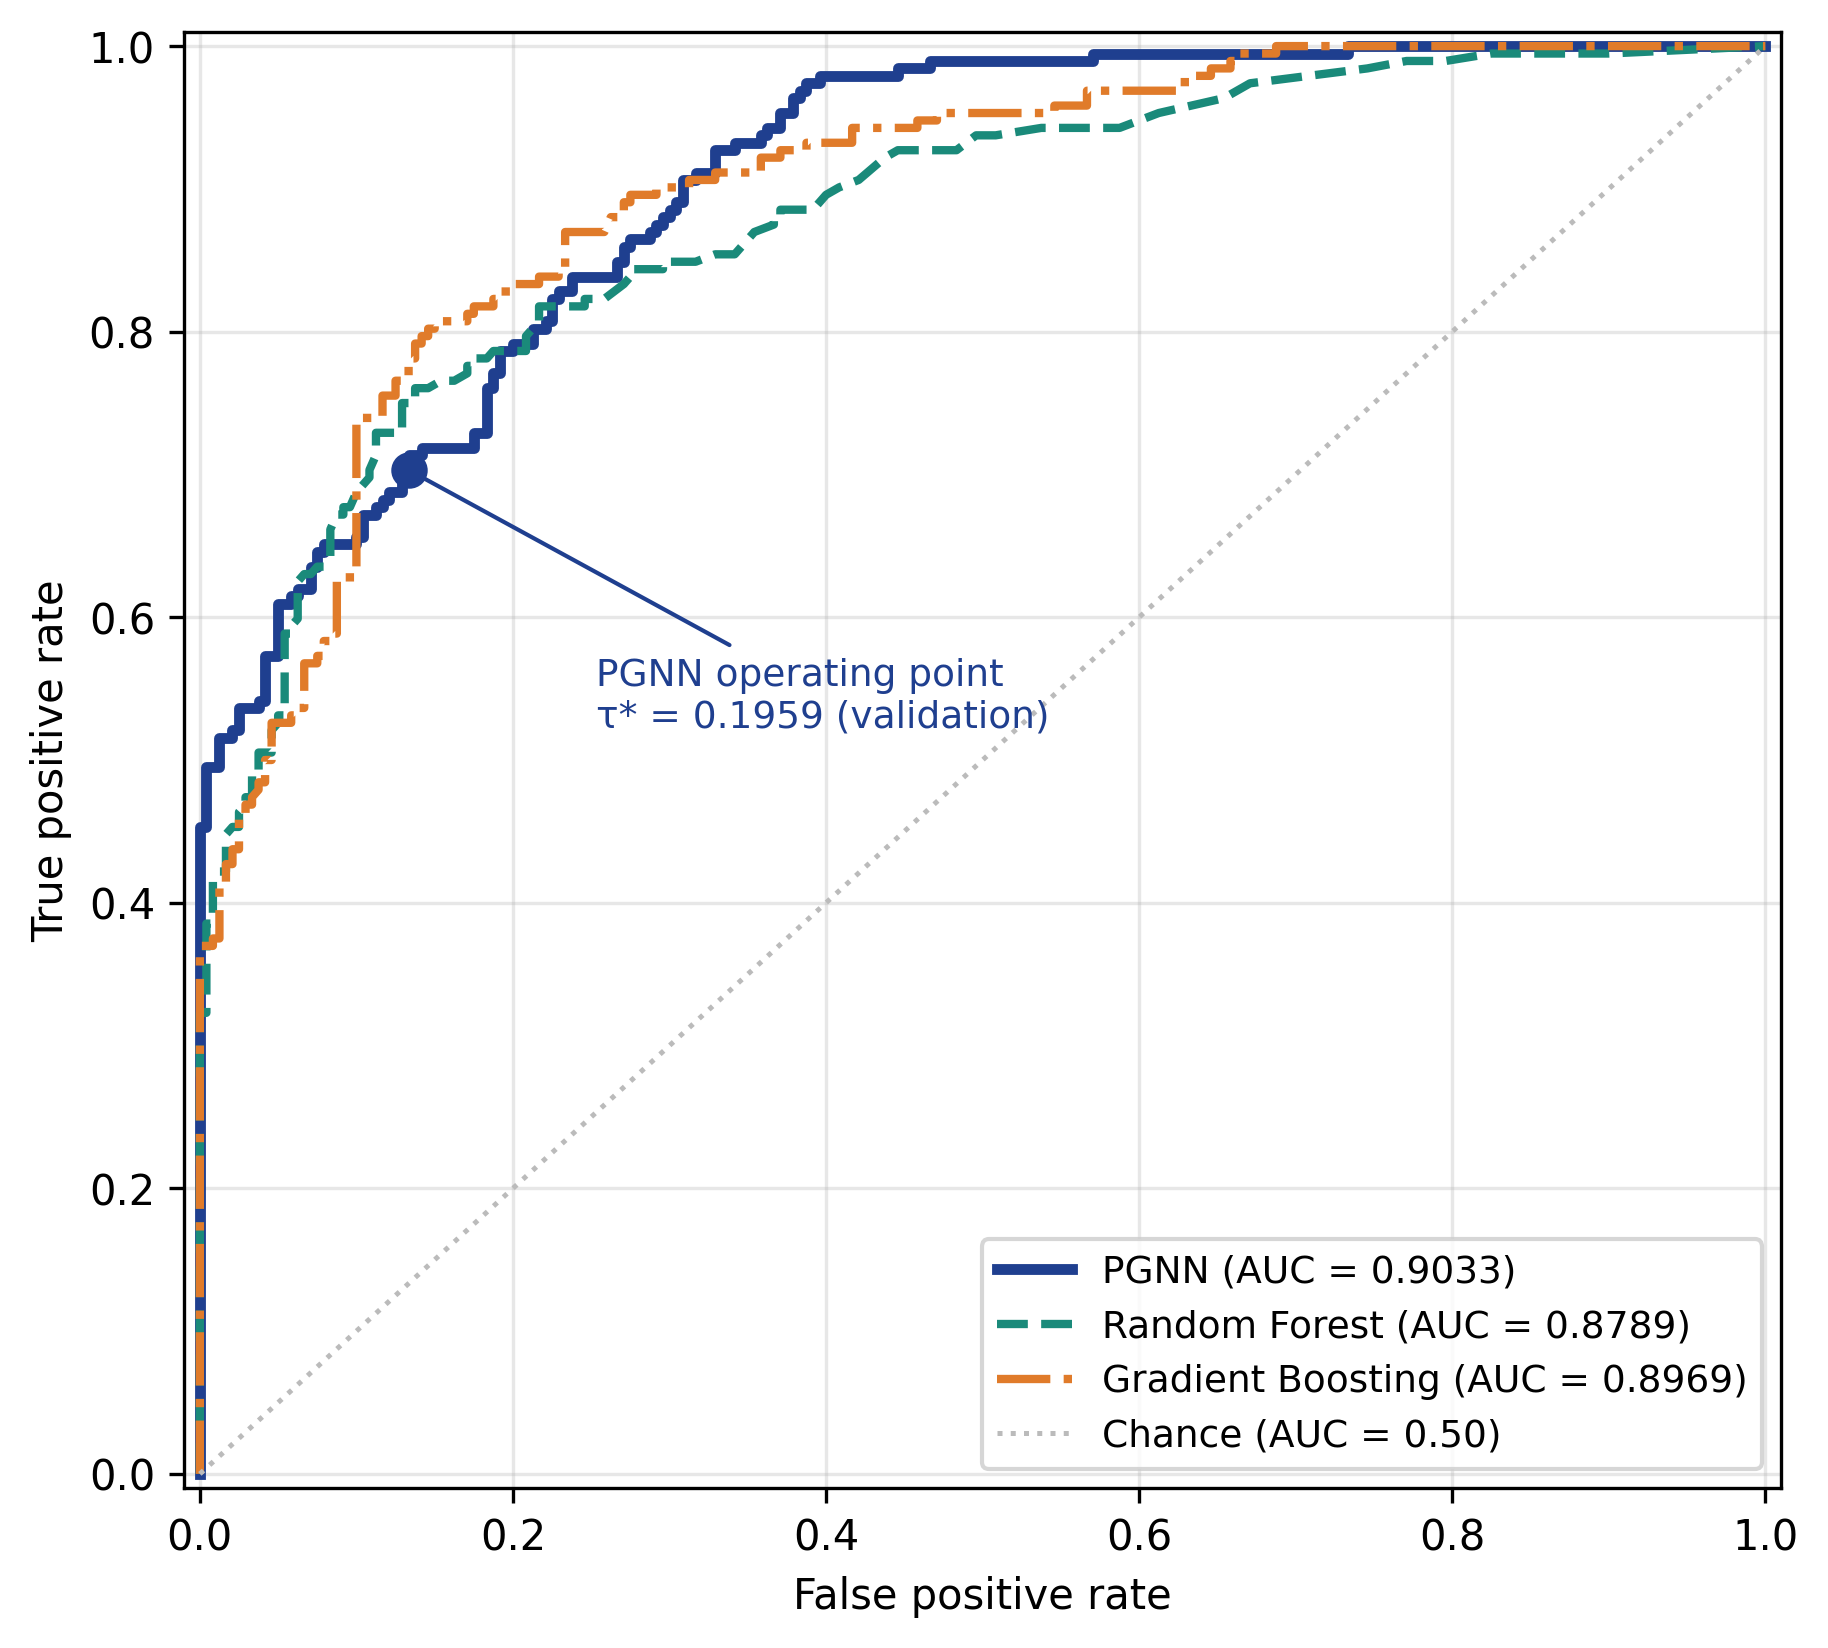

confusion [[TN FP] [FN TP]] (Table 4 / Fig. 5A): [[208, 32], [57, 135]]
13_lambda_sweep_validation.json not uploaded: recomputing the validation lambda sweep (8 seeds)


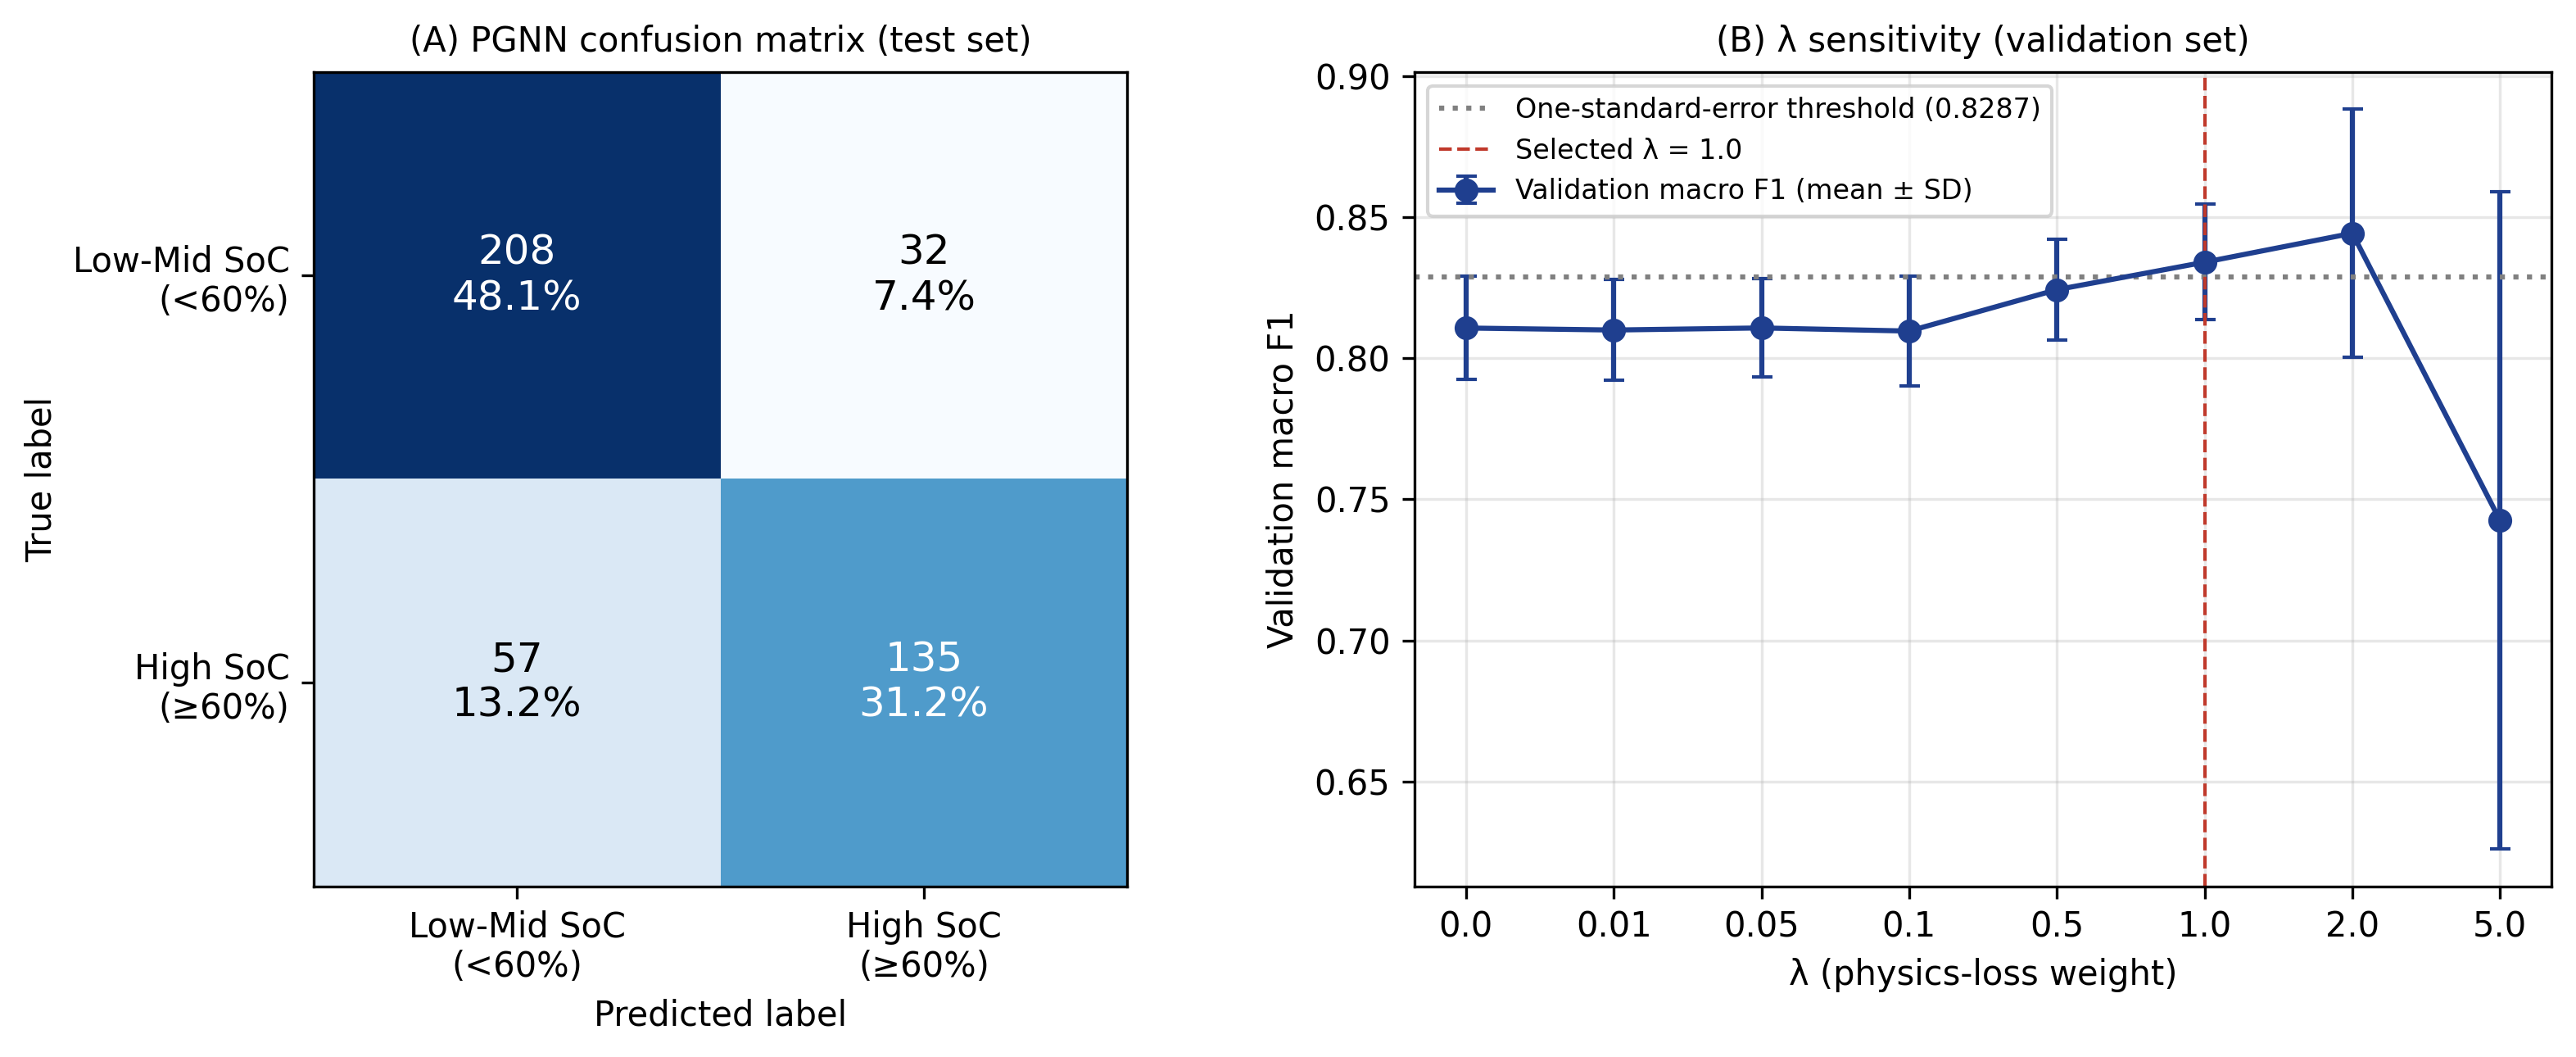

ablation JSONs not uploaded: Figure 6 skipped (upload reviewer3_results.zip and reviewer_results_v2.zip to draw it)
Fig 7A (seed 42): mean P(High) on high-|Z| val windows: [0.407, 0.407, 0.405, 0.402, 0.408, 0.4, 0.376] | High-SoC recall: [0.855, 0.868, 0.877, 0.868, 0.895, 0.895, 0.846]
Fig 7B (seed 0):  mean P(High) on high-|Z| val windows: [0.45, 0.402, 0.356, 0.28, 0.159, 0.091, 0.05]


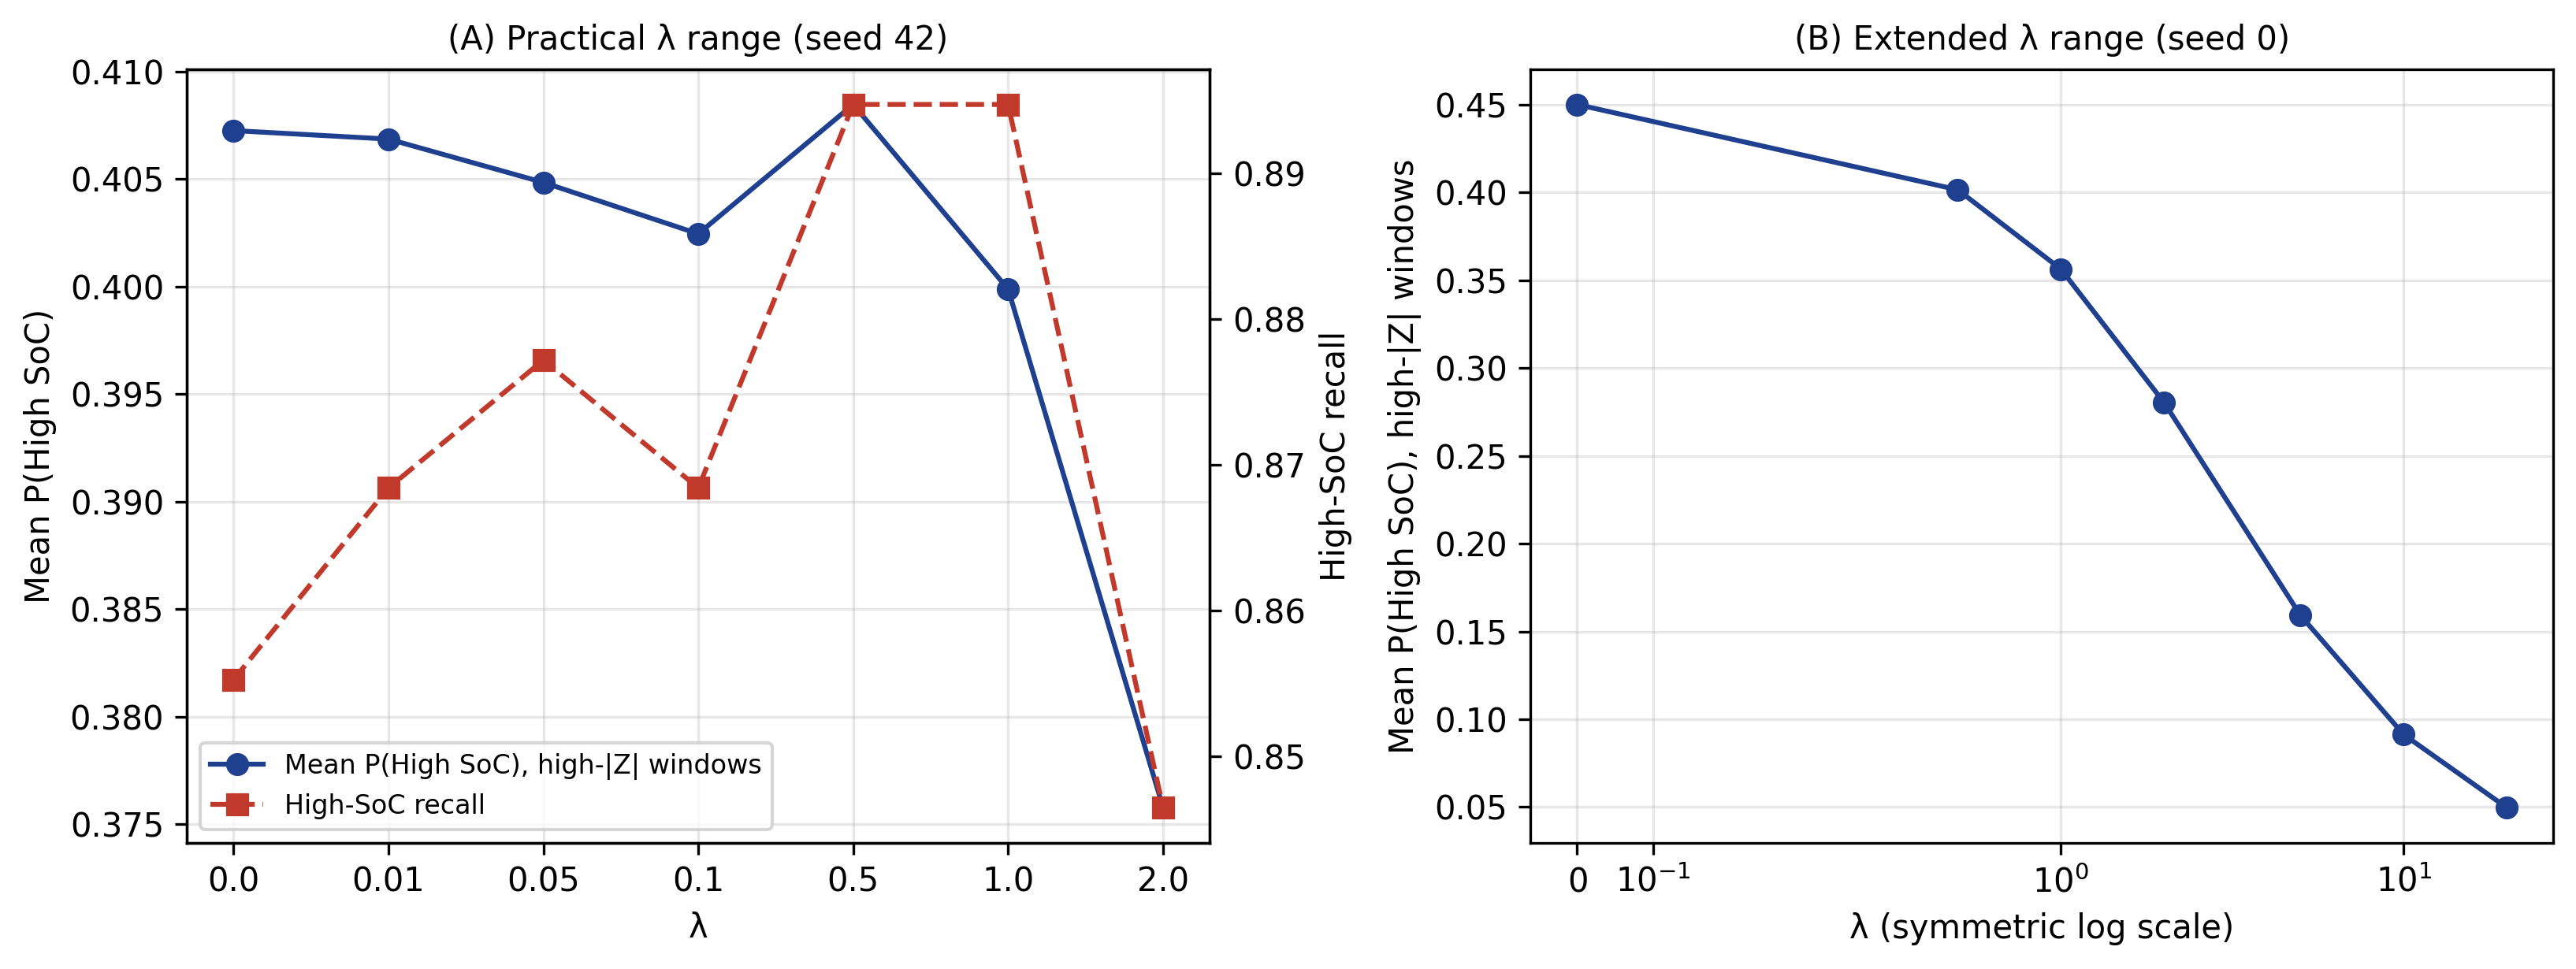

saved results/06_figures.json (51.9 min)


In [9]:
def find_prior(name):
    hits = glob.glob(f"prior/**/{name}", recursive=True); return hits[0] if hits else None

if RUN["figures"]:
    COL = {"PGNN": "#1f3f8f", "RF": "#1a8a7a", "GB": "#e07b2a"}
    # ---- Figure 4 and 5A: seed-42 single run --------------------------------------
    pv, pt = run_pgnn(W, y60, lam=1.0, seed=42); tau = youden(y60[W["va"]], pv)
    yte = y60[W["te"]]; single = {"PGNN": metrics(yte, pt, tau)}; probs = {"PGNN": pt}
    for k, mdl in (("RF", RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=42)),
                   ("GB", GradientBoostingClassifier(n_estimators=300, max_depth=3, learning_rate=0.1, random_state=42))):
        pvb, ptb = run_sklearn(mdl, W, y60); probs[k] = ptb; single[k] = metrics(yte, ptb, youden(y60[W["va"]], pvb))
    print("single run (compare with Table 3):", single)
    fig, ax = plt.subplots(figsize=(6.2, 5.6), dpi=300)
    for k, ls, lw, lab in (("PGNN", "-", 2.6, "PGNN"), ("RF", "--", 2.0, "Random Forest"), ("GB", "-.", 2.0, "Gradient Boosting")):
        fpr, tpr, _ = roc_curve(yte, probs[k]); ax.plot(fpr, tpr, color=COL[k], ls=ls, lw=lw, label=f"{lab} (AUC = {single[k]['auc']:.4f})")
    ax.plot([0, 1], [0, 1], color="#bbbbbb", ls=":", lw=1.2, label="Chance (AUC = 0.50)")
    fp_ = ((pt >= tau) & (yte == 0)).sum() / (yte == 0).sum(); tp_ = ((pt >= tau) & (yte == 1)).sum() / (yte == 1).sum()
    ax.scatter([fp_], [tp_], s=60, color=COL["PGNN"], zorder=5)
    ax.annotate(f"PGNN operating point\nτ* = {tau:.4f} (validation)", (fp_, tp_), xytext=(fp_ + 0.12, tp_ - 0.18),
                arrowprops=dict(arrowstyle="-", color=COL["PGNN"]), fontsize=9, color=COL["PGNN"])
    ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate"); ax.set_xlim(-0.01, 1.01); ax.set_ylim(-0.01, 1.01)
    ax.grid(alpha=0.3); ax.legend(loc="lower right", fontsize=9); fig.tight_layout(); fig.savefig("results/figure4_roc_PGNN.png", dpi=300); plt.show()

    cm = confusion_matrix(yte, (pt >= tau).astype(int)); print("confusion [[TN FP] [FN TP]] (Table 4 / Fig. 5A):", cm.tolist())
    fig, axs = plt.subplots(1, 2, figsize=(11, 4.4), dpi=300)
    ax = axs[0]; ax.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]}\n{cm[i, j] / cm.sum() * 100:.1f}%", ha="center", va="center", fontsize=12,
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1]); ax.set_xticklabels(["Low-Mid SoC\n(<60%)", "High SoC\n(≥60%)"])
    ax.set_yticklabels(["Low-Mid SoC\n(<60%)", "High SoC\n(≥60%)"]); ax.set_xlabel("Predicted label"); ax.set_ylabel("True label")
    ax.set_title("(A) PGNN confusion matrix (test set)", fontsize=10)
    # ---- Figure 5B: lambda sensitivity on validation (Table 7) ---------------------
    LAMS = [0.0, 0.01, 0.05, 0.10, 0.50, 1.0, 2.0, 5.0]
    pj = find_prior("13_lambda_sweep_validation.json")
    if pj:
        lj = json.load(open(pj))["per_lambda"]; lam_mean = [lj[str(l)]["val_f1"][0] for l in LAMS]; lam_sd = [lj[str(l)]["val_f1"][1] for l in LAMS]
        print("Figure 5B from", pj)
    else:
        print("13_lambda_sweep_validation.json not uploaded: recomputing the validation lambda sweep (8 seeds)")
        lam_mean, lam_sd = [], []
        for l in LAMS:
            f = []
            for seed in range(min(8, N_SEEDS) if not QUICK else 2):
                pvl, _ = run_pgnn(W, y60, lam=l, seed=seed); yv = y60[W["va"]]; f.append(f1_score(yv, (pvl >= youden(yv, pvl)).astype(int), average="macro"))
            lam_mean.append(np.mean(f)); lam_sd.append(np.std(f, ddof=1) if len(f) > 1 else 0.0)
    ib = int(np.argmax(lam_mean)); n_l = 8; one_se = lam_mean[ib] - lam_sd[ib] / np.sqrt(n_l)
    ax = axs[1]; xs = np.arange(len(LAMS))
    ax.errorbar(xs, lam_mean, yerr=lam_sd, marker="o", capsize=3, color=COL["PGNN"], label="Validation macro F1 (mean ± SD)")
    ax.axhline(one_se, ls=":", color="grey", label=f"One-standard-error threshold ({one_se:.4f})")
    ax.axvline(LAMS.index(1.0), ls="--", color="#c0392b", lw=1, label="Selected λ = 1.0")
    ax.set_xticks(xs); ax.set_xticklabels([str(l) for l in LAMS]); ax.set_xlabel("λ (physics-loss weight)"); ax.set_ylabel("Validation macro F1")
    ax.set_title("(B) λ sensitivity (validation set)", fontsize=10); ax.legend(fontsize=8); ax.grid(alpha=0.3)
    fig.tight_layout(); fig.savefig("results/figure5_confusion_lambda_PGNN.png", dpi=300); plt.show()

    # ---- Figure 6: ablation (Table 6) ----------------------------------------------
    pa, p1 = find_prior("corrected_split_ablation.json"), find_prior("05_ablation_A1.json")
    if pa and p1:
        A = json.load(open(pa))["summary"]; A1 = json.load(open(p1))["matched"]
        def row(lbl, f, fsd, a, asd, d, p): return (lbl, f, fsd, a, asd, d, p)
        rows = [row("Full\nmodel", A["full"]["mean_macro_f1"], A["full"]["sd_macro_f1"], A["full"]["mean_accuracy"], A["full"]["sd_accuracy"], None, None),
                row("A1: No\nsliding window", A1["f1"][0], A1["f1"][1], A1["acc"][0], A1["acc"][1], A1["vs_full_f1"]["delta"], A1["vs_full_f1"]["p"])]
        for key, lbl in (("A2_no_phase", "A2: No\nphase feature"), ("A3_default_threshold", "A3: Default\nthreshold (τ = 0.5)"), ("A4_no_physics", "A4: No\nphysics loss")):
            e = A[key]; rows.append(row(lbl, e["mean_macro_f1"], e["sd_macro_f1"], e["mean_accuracy"], e["sd_accuracy"], e["delta_f1_vs_full"], e["p_value_vs_full"]))
        print("Figure 6 from", pa, "and", p1)
    else:
        print("ablation JSONs not uploaded: Figure 6 skipped (upload reviewer3_results.zip and reviewer_results_v2.zip to draw it)")
        rows = None
    if rows:
        fig, ax = plt.subplots(figsize=(9, 4.6), dpi=300); xs = np.arange(len(rows)); w = 0.38
        cols = ["#1f3f8f", "#8a8f98", "#8a8f98", "#c0392b", "#c0392b"]
        ax.bar(xs - w / 2, [r[1] for r in rows], w, yerr=[r[2] for r in rows], capsize=3, color=cols, label="Macro F1")
        ax.bar(xs + w / 2, [r[3] for r in rows], w, yerr=[r[4] for r in rows], capsize=3, color=cols, alpha=0.45, hatch="//", label="Accuracy")
        for x, r in zip(xs, rows):
            if r[6] is not None:
                ax.text(x, 0.905, f"ΔF1 = {r[5]:+.4f}\np = {r[6]:.2g}", ha="center", fontsize=7)
        ax.set_xticks(xs); ax.set_xticklabels([r[0] for r in rows], fontsize=8); ax.set_ylim(0.6, 0.93)
        ax.set_ylabel("Test score (mean ± SD, 10 seeds)"); ax.legend(fontsize=8, loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2, frameon=False); ax.grid(axis="y", alpha=0.3)
        fig.tight_layout(); fig.savefig("results/figure6_ablation_PGNN.png", dpi=300); plt.show()

    # ---- Figure 7: does lambda restrict High-SoC predictions? (recomputed) -----------
    hi_va = W["zn"][W["va"]] > 0.5; yv = y60[W["va"]]
    def restriction(l, seed):
        pvl, _ = run_pgnn(W, y60, lam=l, seed=seed); t = youden(yv, pvl)
        return float(pvl[hi_va].mean()), float(recall_score(yv, (pvl >= t).astype(int)))
    LA = [0.0, 0.01, 0.05, 0.10, 0.50, 1.0, 2.0]; LB = [0.0, 0.5, 1.0, 2.0, 5.0, 10.0, 20.0]
    ra = [restriction(l, 42) for l in LA]; rb = [restriction(l, 0)[0] for l in LB]
    print("Fig 7A (seed 42): mean P(High) on high-|Z| val windows:", [round(a, 3) for a, _ in ra], "| High-SoC recall:", [round(b, 3) for _, b in ra])
    print("Fig 7B (seed 0):  mean P(High) on high-|Z| val windows:", [round(v, 3) for v in rb])
    fig, axs = plt.subplots(1, 2, figsize=(11, 4.2), dpi=300)
    ax = axs[0]; xs = np.arange(len(LA)); ax.plot(xs, [a for a, _ in ra], "o-", color=COL["PGNN"], label="Mean P(High SoC), high-|Z| windows")
    ax2 = ax.twinx(); ax2.plot(xs, [b for _, b in ra], "s--", color="#c0392b", label="High-SoC recall")
    ax.set_xticks(xs); ax.set_xticklabels([str(l) for l in LA]); ax.set_xlabel("λ"); ax.set_ylabel("Mean P(High SoC)"); ax2.set_ylabel("High-SoC recall")
    ax.set_title("(A) Practical λ range (seed 42)", fontsize=10); ax.grid(alpha=0.3)
    h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels(); ax.legend(h1 + h2, l1 + l2, fontsize=8)
    ax = axs[1]; ax.plot(LB, rb, "o-", color=COL["PGNN"]); ax.set_xscale("symlog", linthresh=0.5)
    ax.set_xlabel("λ (symmetric log scale)"); ax.set_ylabel("Mean P(High SoC), high-|Z| windows"); ax.set_title("(B) Extended λ range (seed 0)", fontsize=10); ax.grid(alpha=0.3)
    fig.tight_layout(); fig.savefig("results/figure7_lambda_restriction_PGNN.png", dpi=300); plt.show()
    save("06_figures", dict(single_run=single, confusion=cm.tolist(), fig7A=dict(lambdas=LA, mean_p_high=[a for a, _ in ra], recall_high=[b for _, b in ra]),
                            fig7B=dict(lambdas=LB, mean_p_high=rb), fig5B_source=pj or "recomputed", fig6_source=[pa, p1]))

## 7. Versions, requirements, download

In [10]:
versions = dict(python=platform.python_version(), torch=torch.__version__, sklearn=sklearn.__version__, numpy=np.__version__,
                pandas=pd.__version__, scipy=scipy.__version__, matplotlib=matplotlib.__version__, quick_mode=QUICK,
                total_minutes=round((time.time() - T0) / 60, 1))
print(versions); save("07_versions", versions)
with open("results/requirements.txt", "w") as f:
    for pkg, key in (("torch", "torch"), ("scikit-learn", "sklearn"), ("numpy", "numpy"), ("pandas", "pandas"), ("scipy", "scipy"), ("matplotlib", "matplotlib")):
        f.write(f"{pkg}=={versions[key].split('+')[0]}\n")
with zipfile.ZipFile("reviewer4_results.zip", "w") as zf:
    for fn in sorted(os.listdir("results")):
        zf.write(os.path.join("results", fn), fn)
print("wrote reviewer4_results.zip with", len(os.listdir("results")), "files")
try:
    from google.colab import files; files.download("reviewer4_results.zip")
except ImportError:
    pass

{'python': '3.13.16', 'torch': '2.11.0+cpu', 'sklearn': '1.6.1', 'numpy': '2.1.3', 'pandas': '2.2.3', 'scipy': '1.16.3', 'matplotlib': '3.10.0', 'quick_mode': False, 'total_minutes': 51.9}
saved results/07_versions.json (51.9 min)
wrote reviewer4_results.zip with 13 files


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>